# Fitness Evolution Visualization

Plots fitness (F1-macro) evolution across PSO iterations for each experimental configuration.

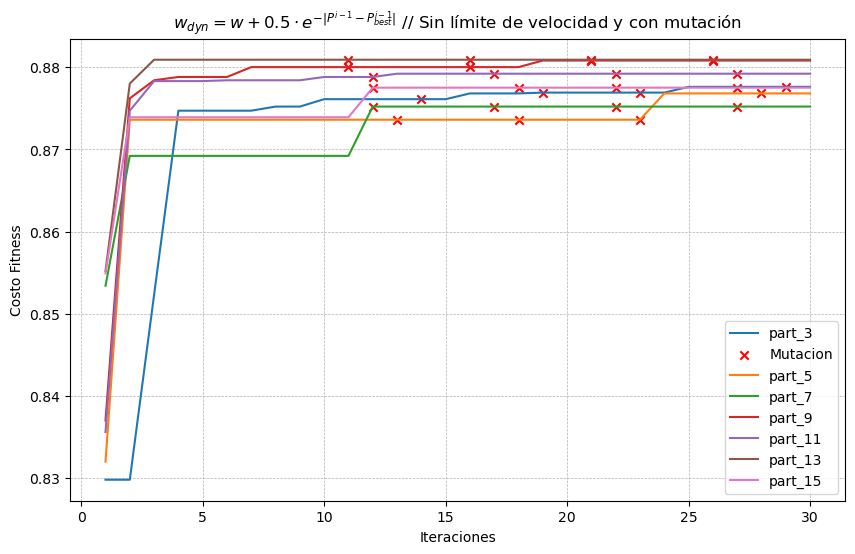

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('../results/w_evol_mut_nospeedlimit/w_evol_mut_nospeedlimit.csv', sep=',')

# Mapping from run index to particle count label
run_mapping = {
    1: 'part_3',
    2: 'part_5',
    3: 'part_7',
    4: 'part_9',
    5: 'part_11',
    6: 'part_13',
    7: 'part_15'
}

plt.figure(figsize=(10, 6))
mutation_legend_added = False

for run, label in run_mapping.items():
    subset = df[df['Run'] == run]
    plt.plot(subset['Iteracion'], subset['CostoFitness'], linestyle='-', label=label)
    # Mark iterations where a mutation occurred
    if 'NumPartMut' in df.columns:
        mutations = subset[subset['NumPartMut'] > 0]
        if not mutations.empty:
            plt.scatter(mutations['Iteracion'], mutations['CostoFitness'],
                        color='red', marker='x',
                        label="Mutation" if not mutation_legend_added else "")
            mutation_legend_added = True

plt.xlabel("Iterations")
plt.ylabel("Fitness Cost")
plt.title(r"$w_{dyn} = w + 0.5 \cdot e^{-|P^{i-1} - P^{i-1}_{best}|}$ — No speed limit, with mutation")
plt.legend()
plt.grid(True, linestyle='--', linewidth=0.5)
plt.show()
